In [3]:
import pandas as pd
import numpy as np


In [2]:
!pip install gensim

In [4]:
import gensim
import os

In [5]:
import zipfile, os
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

zipfile.ZipFile('Game of throne.zip').extractall('data')

story = []
for filename in os.listdir('data'):
    f = open(os.path.join('data', filename), encoding='utf-8', errors='ignore')
    corpus = f.read()
    raw_sent = sent_tokenize(corpus)
    for sent in raw_sent:
        story.append(simple_preprocess(sent))



In [6]:
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

story = []
for filename in os.listdir('data'):

    f = open(os.path.join('data', filename))
    corpus = f.read()
    # break sentence
    raw_sent = sent_tokenize(corpus)
    for sent in raw_sent:
        story.append(simple_preprocess(sent))

In [7]:
len(story)

145020

In [8]:
story

[['game',
  'of',
  'thrones',
  'book',
  'one',
  'of',
  'song',
  'of',
  'ice',
  'and',
  'fire',
  'by',
  'george',
  'martin',
  'prologue',
  'we',
  'should',
  'start',
  'back',
  'gared',
  'urged',
  'as',
  'the',
  'woods',
  'began',
  'to',
  'grow',
  'dark',
  'around',
  'them'],
 ['the', 'wildlings', 'are', 'dead'],
 ['do', 'the', 'dead', 'frighten', 'you'],
 ['ser',
  'waymar',
  'royce',
  'asked',
  'with',
  'just',
  'the',
  'hint',
  'of',
  'smile'],
 ['gared', 'did', 'not', 'rise', 'to', 'the', 'bait'],
 ['he',
  'was',
  'an',
  'old',
  'man',
  'past',
  'fifty',
  'and',
  'he',
  'had',
  'seen',
  'the',
  'lordlings',
  'come',
  'and',
  'go'],
 ['dead', 'is', 'dead', 'he', 'said'],
 ['we', 'have', 'no', 'business', 'with', 'the', 'dead'],
 ['are', 'they', 'dead'],
 ['royce', 'asked', 'softly'],
 ['what', 'proof', 'have', 'we'],
 ['will', 'saw', 'them', 'gared', 'said'],
 ['if',
  'he',
  'says',
  'they',
  'are',
  'dead',
  'that',
  'proof',


In [9]:
model = gensim.models.Word2Vec(
    window=10,
    min_count = 2,
    workers = 4,
)

In [10]:
model.build_vocab(story)

In [11]:
model.train(story, total_examples=model.corpus_count, epochs=model.epochs)

(6570057, 8628190)

In [12]:
model.wv.most_similar('daenerys')

[('stormborn', 0.7810225486755371),
 ('targaryen', 0.7797951698303223),
 ('unburnt', 0.7204710841178894),
 ('princess', 0.7025370001792908),
 ('queen', 0.6989243626594543),
 ('elia', 0.6947693228721619),
 ('myrcella', 0.6895269751548767),
 ('viserys', 0.6691254377365112),
 ('rhaegar', 0.655440628528595),
 ('margaery', 0.6509506702423096)]

In [13]:
model.wv.doesnt_match(['jon','rikon','robb','arya','sansa','bran'])

'jon'

In [14]:
model.wv.doesnt_match(['cersei','jaime','bronn','tyrion'])

'bronn'

In [15]:
# particular's word vector representation
model.wv['jon']

array([-0.7614817 , -1.0414368 ,  0.07062687, -1.2722274 ,  0.6224377 ,
        1.3565701 ,  1.3575926 , -0.28547004, -0.90776974,  0.12164883,
        0.64443505,  0.06659305, -0.4458609 , -2.842475  ,  0.17175052,
       -0.88704807,  1.866068  ,  4.0660605 , -0.72845274, -1.2757754 ,
        1.5629634 , -1.9007598 ,  0.2992425 ,  1.4299182 , -0.8980485 ,
       -1.7037857 ,  2.3517065 ,  0.6040205 ,  1.1397822 , -0.2550803 ,
       -2.6646938 , -0.37115863,  0.4450594 , -0.75093573,  0.47812328,
        0.98591155,  2.6777031 , -0.77703124,  0.5632691 ,  0.6511693 ,
       -1.1459285 , -1.8261492 ,  1.7091973 ,  1.052208  ,  0.09485526,
       -1.796274  , -0.790672  ,  1.0237288 , -1.1816078 ,  0.1373294 ,
       -0.6665465 , -0.23681514,  0.67556936, -0.15546514, -0.6917661 ,
        0.54305625, -1.3583082 , -1.3781294 ,  0.61642766, -0.5679712 ,
       -1.698024  ,  1.7929242 ,  1.7777972 , -1.4201697 , -0.9708784 ,
        0.3904693 ,  0.2078849 ,  2.45765   , -1.2481161 ,  1.17

In [16]:
model.wv.similarity('arya','sansa')

np.float32(0.8518549)

In [17]:
model.wv.similarity('cersei','sansa')

np.float32(0.7603753)

In [18]:
model.wv.similarity('tywin','sansa')

np.float32(0.2769377)

In [19]:
model.wv.get_normed_vectors()

array([[-0.001779  , -0.05330224,  0.15583245, ..., -0.05601365,
        -0.10992073,  0.07641947],
       [-0.0331329 , -0.12559724,  0.11733027, ..., -0.12340543,
        -0.06801497,  0.19567184],
       [ 0.18922763, -0.02650793, -0.0821083 , ..., -0.05803678,
         0.04230779, -0.13471901],
       ...,
       [ 0.01781149,  0.00422489, -0.0615304 , ..., -0.02030843,
         0.08809423, -0.20353635],
       [ 0.03750028,  0.08678284,  0.07240523, ..., -0.22102986,
         0.19560598, -0.06600528],
       [ 0.16801153,  0.13486324,  0.05475206, ...,  0.15058205,
         0.00213285, -0.08814974]], shape=(17453, 100), dtype=float32)

In [20]:
model.wv.get_normed_vectors().shape

(17453, 100)

In [21]:
y = model.wv.index_to_key

In [22]:
y

['the',
 'and',
 'to',
 'of',
 'he',
 'his',
 'was',
 'you',
 'her',
 'in',
 'it',
 'had',
 'that',
 'she',
 'as',
 'with',
 'him',
 'not',
 'but',
 'for',
 'they',
 'is',
 'at',
 'on',
 'said',
 'my',
 'have',
 'be',
 'lord',
 'them',
 'no',
 'from',
 'would',
 'were',
 'me',
 'your',
 'one',
 'all',
 'when',
 'will',
 'ser',
 'if',
 'so',
 'their',
 'we',
 'could',
 'are',
 'man',
 'there',
 'this',
 'up',
 'been',
 'what',
 'did',
 'by',
 'king',
 'do',
 'men',
 'back',
 'out',
 'more',
 'or',
 'who',
 'down',
 'well',
 'than',
 'only',
 'like',
 'jon',
 'some',
 'father',
 'old',
 'hand',
 'even',
 'too',
 'tyrion',
 'before',
 'never',
 'an',
 'off',
 'know',
 'see',
 'into',
 'made',
 'now',
 'eyes',
 'black',
 'told',
 'lady',
 'thought',
 'time',
 'then',
 'how',
 'long',
 'has',
 'can',
 'might',
 'us',
 'come',
 'where',
 'here',
 'through',
 'face',
 'still',
 'head',
 'red',
 'll',
 'way',
 'boy',
 'page',
 'must',
 'once',
 'queen',
 'good',
 'two',
 'brother',
 'night',
 

In [23]:
len(y)

17453

In [24]:
from sklearn.decomposition import PCA

In [25]:
pca = PCA(n_components=3)

In [26]:
X = pca.fit_transform(model.wv.get_normed_vectors())

In [27]:
X[:5]

array([[ 0.1491933 ,  0.61215997, -0.04362482],
       [ 0.15266691,  0.331801  ,  0.04281321],
       [-0.28156984,  0.57215834,  0.21648207],
       [ 0.00554615,  0.3660605 , -0.09006542],
       [-0.09358534,  0.55479133,  0.24947241]], dtype=float32)

In [28]:
X.shape

(17453, 3)

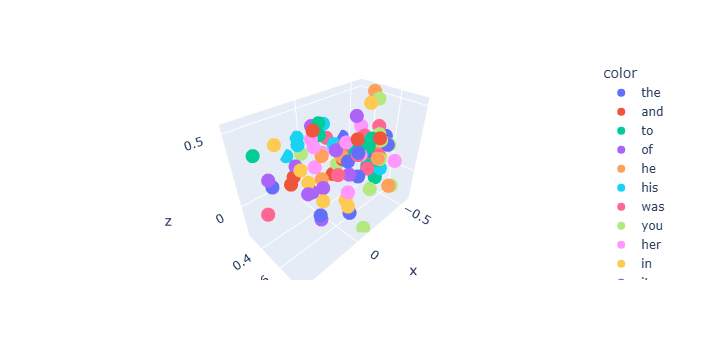

In [29]:
import plotly.express as px

fig = px.scatter_3d(
    x = X[:100, 0], 
    y = X[:100, 1], 
    z = X[:100, 2], 
    color = y[:100]
)
fig.show()

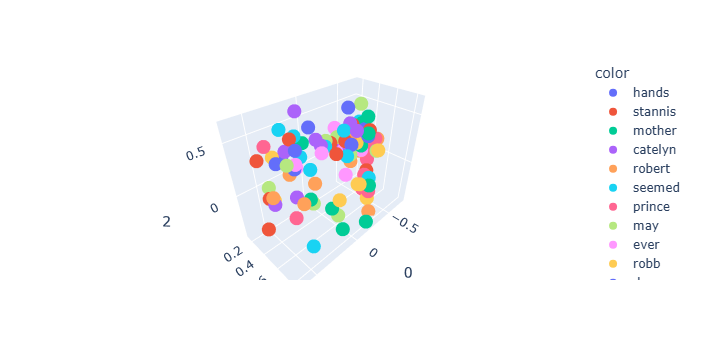

In [31]:
fig = px.scatter_3d( X[200:300], 
    x =0,
    y =1, 
    z =2, 
    color = y[200:300]
)
fig.show()